# Лабораторная работа 5 Классификация
К. Р. Халикова, группа 4417. Вариант 1, как в ЛР4 по указанию преподавателя.

**Цель:** изучение алгоритмов и методов классификации на практике.

## Задание на лабораторную работу
Используется medical_diagnosis.csv. Требуется подготовить данные, исключить целевой Disease из признаков, построить матрицу диаграмм с окраской по классу, проверить баланс, разделить train/test и обучить четыре классификатора: kNN, дерево решений, логистическую регрессию и случайный лес. Для каждого вычисляются Accuracy, Precision, Recall, Balanced accuracy, F1, матрица ошибок; ROC-кривые сравниваются на одном графике.

В основной работе используются восемь числовых признаков. Сравнение с порядковым и прямым кодированием категорий в методичке выделено в дополнительные задания и здесь не выполняется. Это ограничивает набор информации для предсказания и не означает, что категории нельзя использовать в классификации.

## 1 Загрузка и проверка данных
Каждая строка описывает пациента. Disease=1 означает наличие заболевания по разметке файла, Disease=0 его отсутствие. Проверяются типы, пропуски и полные дубликаты. Пропуски не заполняются без необходимости. Высокие лабораторные значения сохраняются: они не признаны ошибками измерения.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import balanced_accuracy_score, f1_score, confusion_matrix
from sklearn.metrics import roc_curve, roc_auc_score

data = pd.read_csv('medical_diagnosis.csv')
print('Исходный размер:', data.shape)
data.info()
print('Пропуски:', data.isna().sum().sum())
print('Полные дубликаты:', data.duplicated().sum())
data = data.drop_duplicates().copy()
print('После удаления дубликатов:', data.shape)
display(data.describe().round(3))

Исходный размер: (3031, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3031 entries, 0 to 3030
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    3031 non-null   int64  
 1   sex                    3031 non-null   object 
 2   BMI                    3031 non-null   float64
 3   systolic_bp            3031 non-null   float64
 4   cholesterol_mg_dl      3031 non-null   float64
 5   fasting_glucose_mg_dl  3031 non-null   float64
 6   smoking_status         3031 non-null   object 
 7   family_history         3031 non-null   object 
 8   activity_level         3031 non-null   object 
 9   symptom_score          3031 non-null   float64
 10  CRP_mg_L               3031 non-null   float64
 11  WBC_10e9_L             3031 non-null   float64
 12  ECG_result             3031 non-null   object 
 13  Disease                3031 non-null   int64  
dtypes: float64(7), int64(2), obj

,age,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,symptom_score,CRP_mg_L,WBC_10e9_L,Disease
count,3030.000,3030.000,3030.000,3030.000,3030.000,3030.000,3030.000,3030.000,3030.000
mean,53.178,26.466,122.414,202.667,94.367,2.040,1.373,6.823,0.016
std,20.743,5.871,17.862,53.573,19.550,1.358,3.131,1.978,0.126
min,18.000,13.500,82.000,85.000,56.000,0.000,0.100,2.300,0.000
25%,35.000,22.500,110.000,171.000,80.250,1.000,0.100,5.480,0.000
50%,53.000,26.300,122.000,200.000,94.000,2.000,0.520,6.750,0.000
75%,71.000,30.400,134.000,232.000,107.000,3.000,1.460,8.150,0.000
max,89.000,50.900,184.000,658.200,163.000,6.800,43.450,13.720,1.000


### Результат проверки
В исходном файле 3031 строка и 14 столбцов. Пропусков нет, найден один полный дубликат. Он удалён до разделения данных, чтобы одинаковые записи не попадали в обучение и тест. Осталось 3030 наблюдений. Заполнение пропусков и автоматическое удаление выбросов не применялись.

## 2 Признаки и матрица диаграмм
Целевая переменная Disease выделяется в y и исключается из X. Вход содержит age, BMI, systolic_bp, cholesterol_mg_dl, fasting_glucose_mg_dl, symptom_score, CRP_mg_L, WBC_10e9_L. Пять категориальных столбцов не включаются в основную модель.

На диагонали матрицы показаны гистограммы, вне диагонали пары числовых признаков в исходных единицах. Цвет означает исходный Disease, а не прогноз. Это предварительное изучение данных, не обучение модели; параметры преобразований по этому графику не подбираются.

Входные признаки: ['age', 'BMI', 'systolic_bp', 'cholesterol_mg_dl', 'fasting_glucose_mg_dl', 'symptom_score', 'CRP_mg_L', 'WBC_10e9_L']


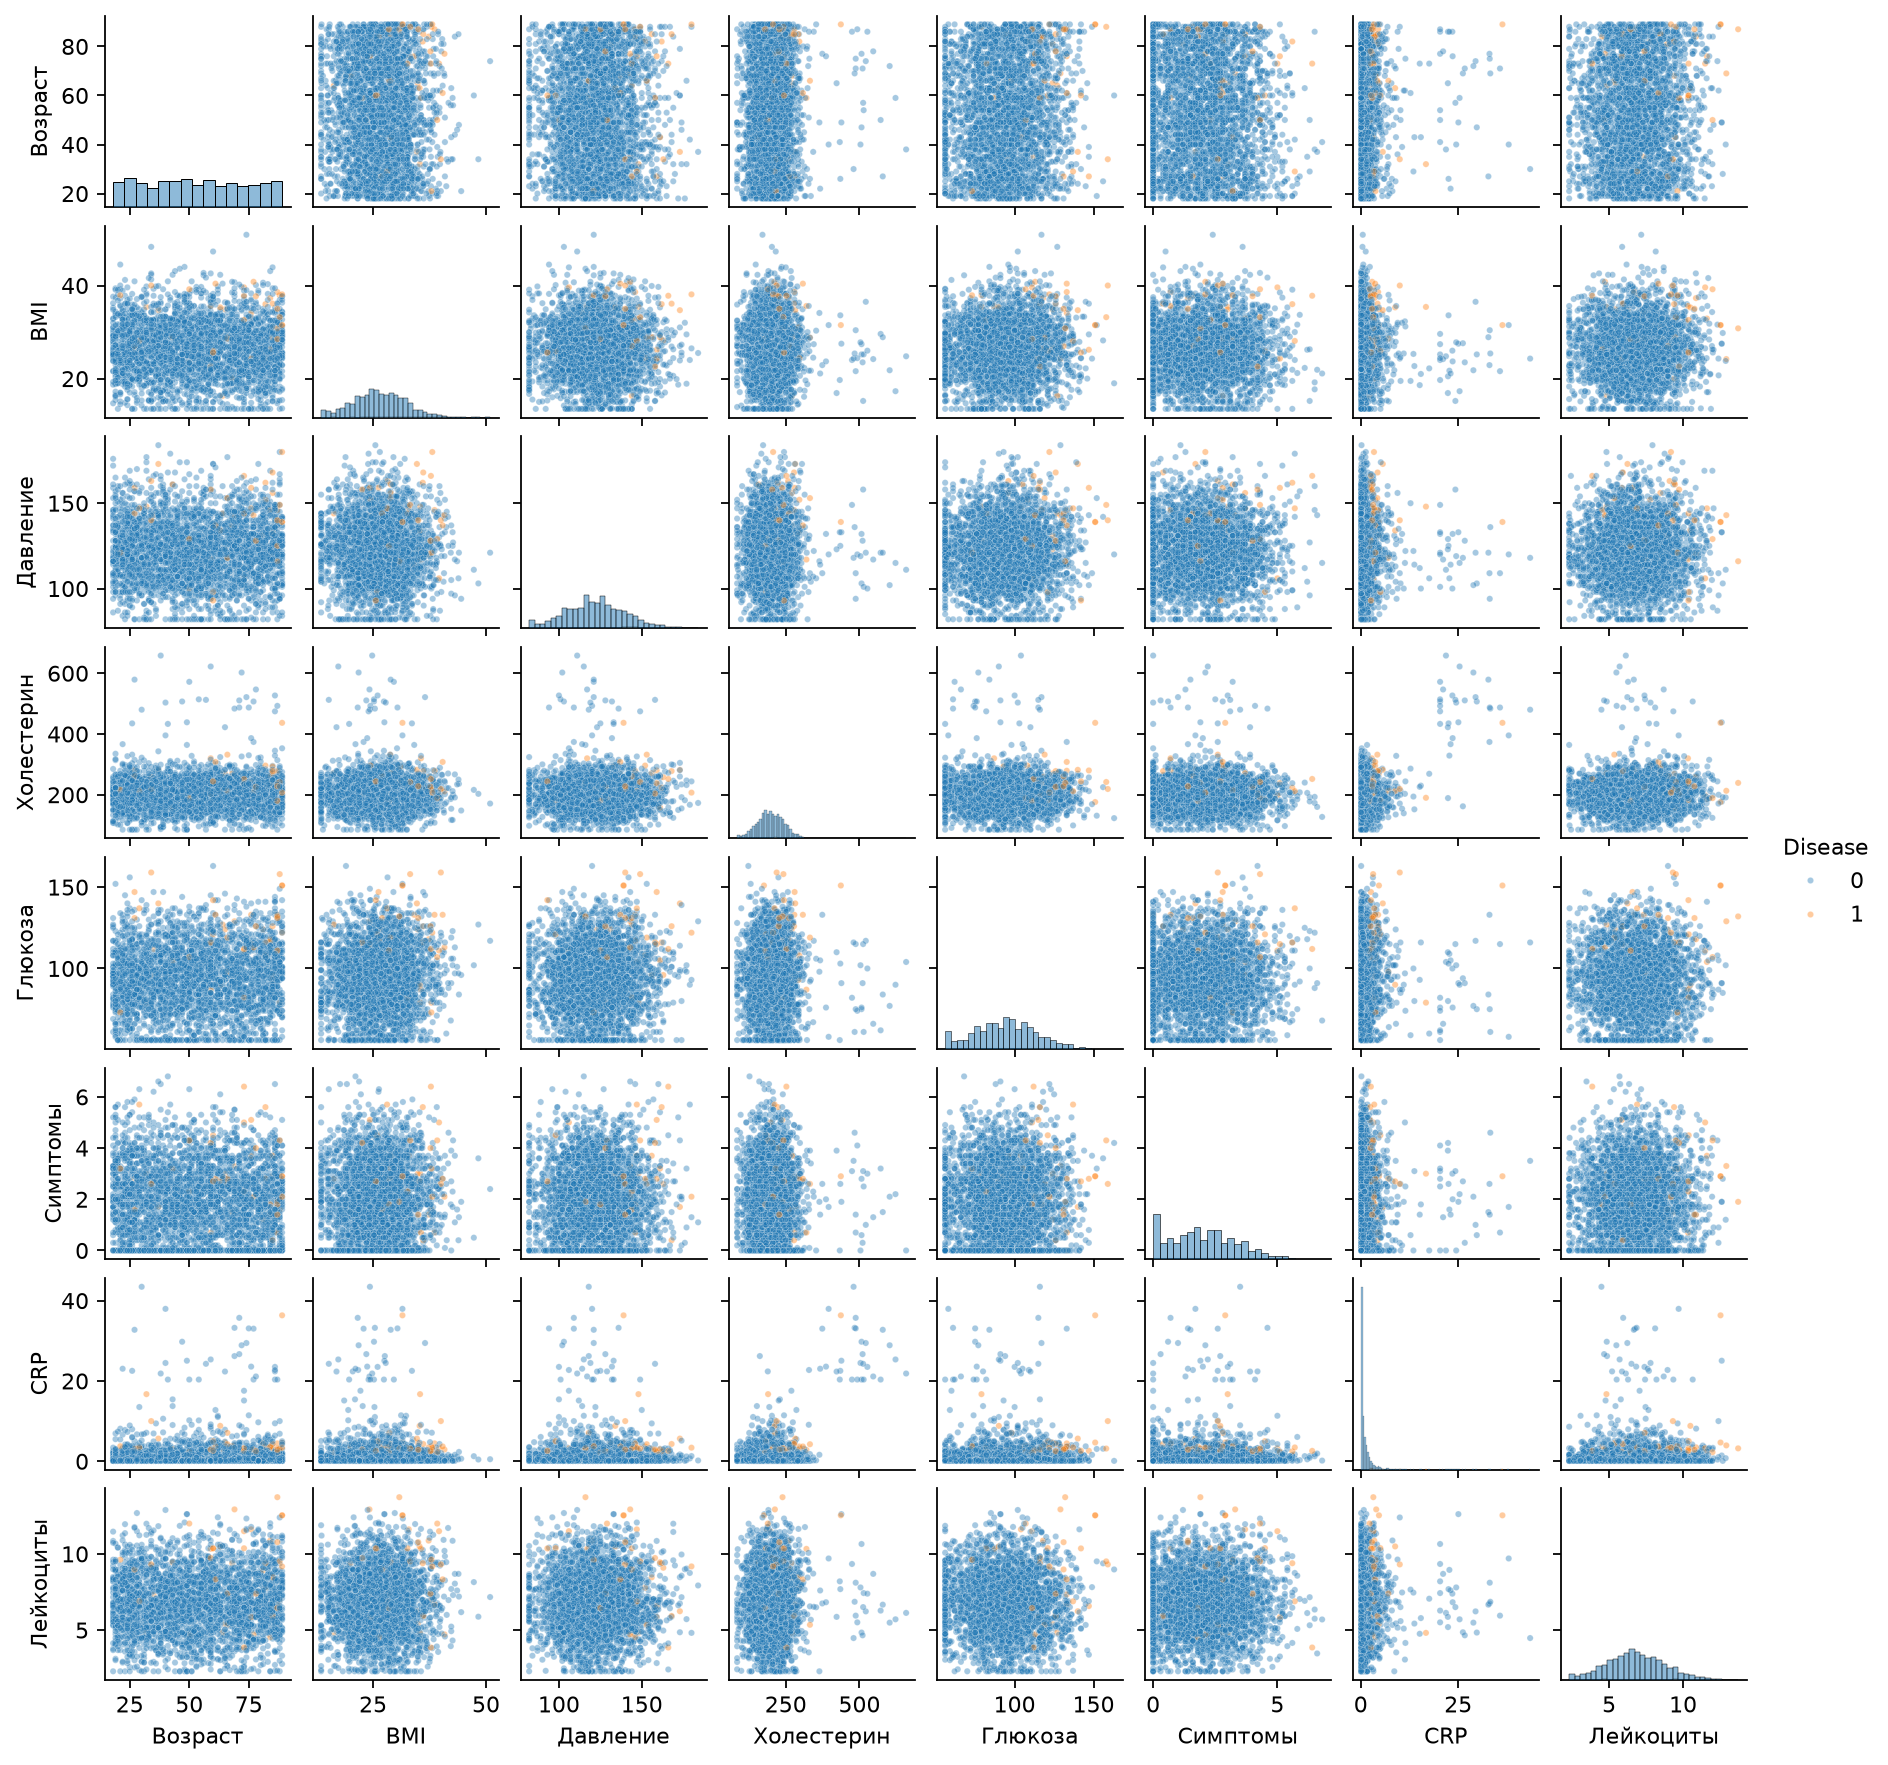

In [2]:
y = data['Disease']
X = data.drop(columns='Disease').select_dtypes(include='number')
print('Входные признаки:', X.columns.tolist())
pair_data = X.rename(columns={
    'age': 'Возраст', 'systolic_bp': 'Давление',
    'cholesterol_mg_dl': 'Холестерин',
    'fasting_glucose_mg_dl': 'Глюкоза', 'symptom_score': 'Симптомы',
    'CRP_mg_L': 'CRP', 'WBC_10e9_L': 'Лейкоциты'})
pair_data['Disease'] = y
sns.pairplot(pair_data, hue='Disease', diag_kind='hist',
             plot_kws={'s': 8, 'alpha': 0.4}, height=1.4)
plt.show()

### Наблюдения по матрице
Исходные классы заметно перекрываются на двумерных проекциях. Видны высокие значения CRP и холестерина у небольшой части наблюдений. По отдельным проекциям нельзя доказать разделимость классов во всём пространстве признаков.

## 3 Баланс классов и организация эксперимента
Подсчитываются численности и доли классов. После удаления дубликата имеется 2981 объект класса 0 и 49 класса 1 (около 1,62%). Поэтому Accuracy сама по себе может вводить в заблуждение.

Выбрано разделение 80/20 с random_state=21 и stratify=y: сохраняются доли классов, тест не используется для настройки. StandardScaler обучается только на X_train; к X_test применяется transform с найденными на train параметрами.

Для дерева, логистической регрессии и леса выбран class_weight='balanced': больший вес редкого класса компенсирует его малую представленность в функции обучения. Это самостоятельное решение по фактическому дисбалансу, а не требование конкретного аргумента из методички. Число строк не изменяется. У kNN такого параметра нет; он остаётся базовой моделью с пятью соседями. Дополнительное пересэмплирование не выполняется. Сравниваются четыре явно заданные конфигурации, оптимальность настроек не заявляется.

In [3]:
class_counts = y.value_counts().sort_index()
display(pd.DataFrame({'count': class_counts,
                      'share': class_counts / len(y)}))
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=21, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Размеры train и test:', X_train.shape, X_test.shape)
display(pd.DataFrame({'train': y_train.value_counts(),
                      'test': y_test.value_counts()}).sort_index())
majority_pred = np.full(len(y_test), y_train.mode().iloc[0])
print('Accuracy постоянного прогноза класса 0:', accuracy_score(y_test, majority_pred))
print('Recall постоянного прогноза:', recall_score(y_test, majority_pred))
print('Balanced accuracy постоянного прогноза:', balanced_accuracy_score(y_test, majority_pred))

Размеры train и test: (2424, 8) (606, 8)
Accuracy постоянного прогноза класса 0: 0.9834983498349835
Recall постоянного прогноза: 0.0
Balanced accuracy постоянного прогноза: 0.5


,count,share
Disease,,
0,2981,0.983828
1,49,0.016172


,train,test
Disease,,
0,2385,596
1,39,10


## 4 Обучение четырёх классификаторов и метрики
kNN определяет класс по голосованию пяти соседей. Дерево использует последовательность условий; max_depth=5 ограничивает сложность. Логистическая регрессия оценивает вероятность класса 1; max_iter=1000 задаёт запас итераций для сходимости. Лес объединяет 100 деревьев. random_state=21 фиксирует случайность дерева и леса. Настройки выбраны заранее, GridSearchCV и подбор по test не выполняются.

Все модели получают одни и те же стандартизованные train/test; для деревьев масштабирование не обязательно, но позволяет сохранить общую подготовку. Precision, Recall и F1 рассчитываются для положительного Disease=1. zero_division=0 задаёт значение 0 при отсутствии предсказанного положительного класса, чтобы явно отразить такой результат.

Accuracy=(TP+TN)/N; ошибка классификации=1−Accuracy; Precision=TP/(TP+FP); Recall=TP/(TP+FN); Balanced accuracy=(TPR+TNR)/2; F1=2TP/(2TP+FP+FN). Метрики отражают разные свойства и рассматриваются совместно. ROC AUC рассчитывается по вероятностям, а не по меткам классов.

In [4]:
models = {
    'kNN': KNeighborsClassifier(n_neighbors=5),
    'Дерево': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=21),
    'Логистическая регрессия': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Случайный лес': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=21)
}
rows = []
predictions = {}
probabilities = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    proba = model.predict_proba(X_test_scaled)[:, 1]
    predictions[name] = pred
    probabilities[name] = proba
    rows.append({
        'Метод': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Ошибка': 1 - accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred),
        'Balanced accuracy': balanced_accuracy_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC AUC': roc_auc_score(y_test, proba)
    })
metrics = pd.DataFrame(rows).set_index('Метод')
display(metrics.round(4))

,Accuracy,Ошибка,Precision,Recall,Balanced accuracy,F1,ROC AUC
Метод,,,,,,,
kNN,0.9851,0.0149,1.0000,0.1,0.5500,0.1818,0.7435
Дерево,0.9488,0.0512,0.1613,0.5,0.7282,0.2439,0.7278
Логистическая регрессия,0.8911,0.1089,0.1216,0.9,0.8955,0.2143,0.9525
Случайный лес,0.9884,0.0116,0.8000,0.4,0.6992,0.5333,0.9801


## 5 Матрицы ошибок
Матрицы строятся отдельно для каждой модели. Строки соответствуют истинным классам, столбцы предсказанным. Порядок классов задан как [0,1], поэтому матрица имеет вид [[TN,FP],[FN,TP]]. FN означает пропуск класса 1; FP ложное отнесение класса 0 к классу 1. Цвет и число в клетке показывают количество объектов.

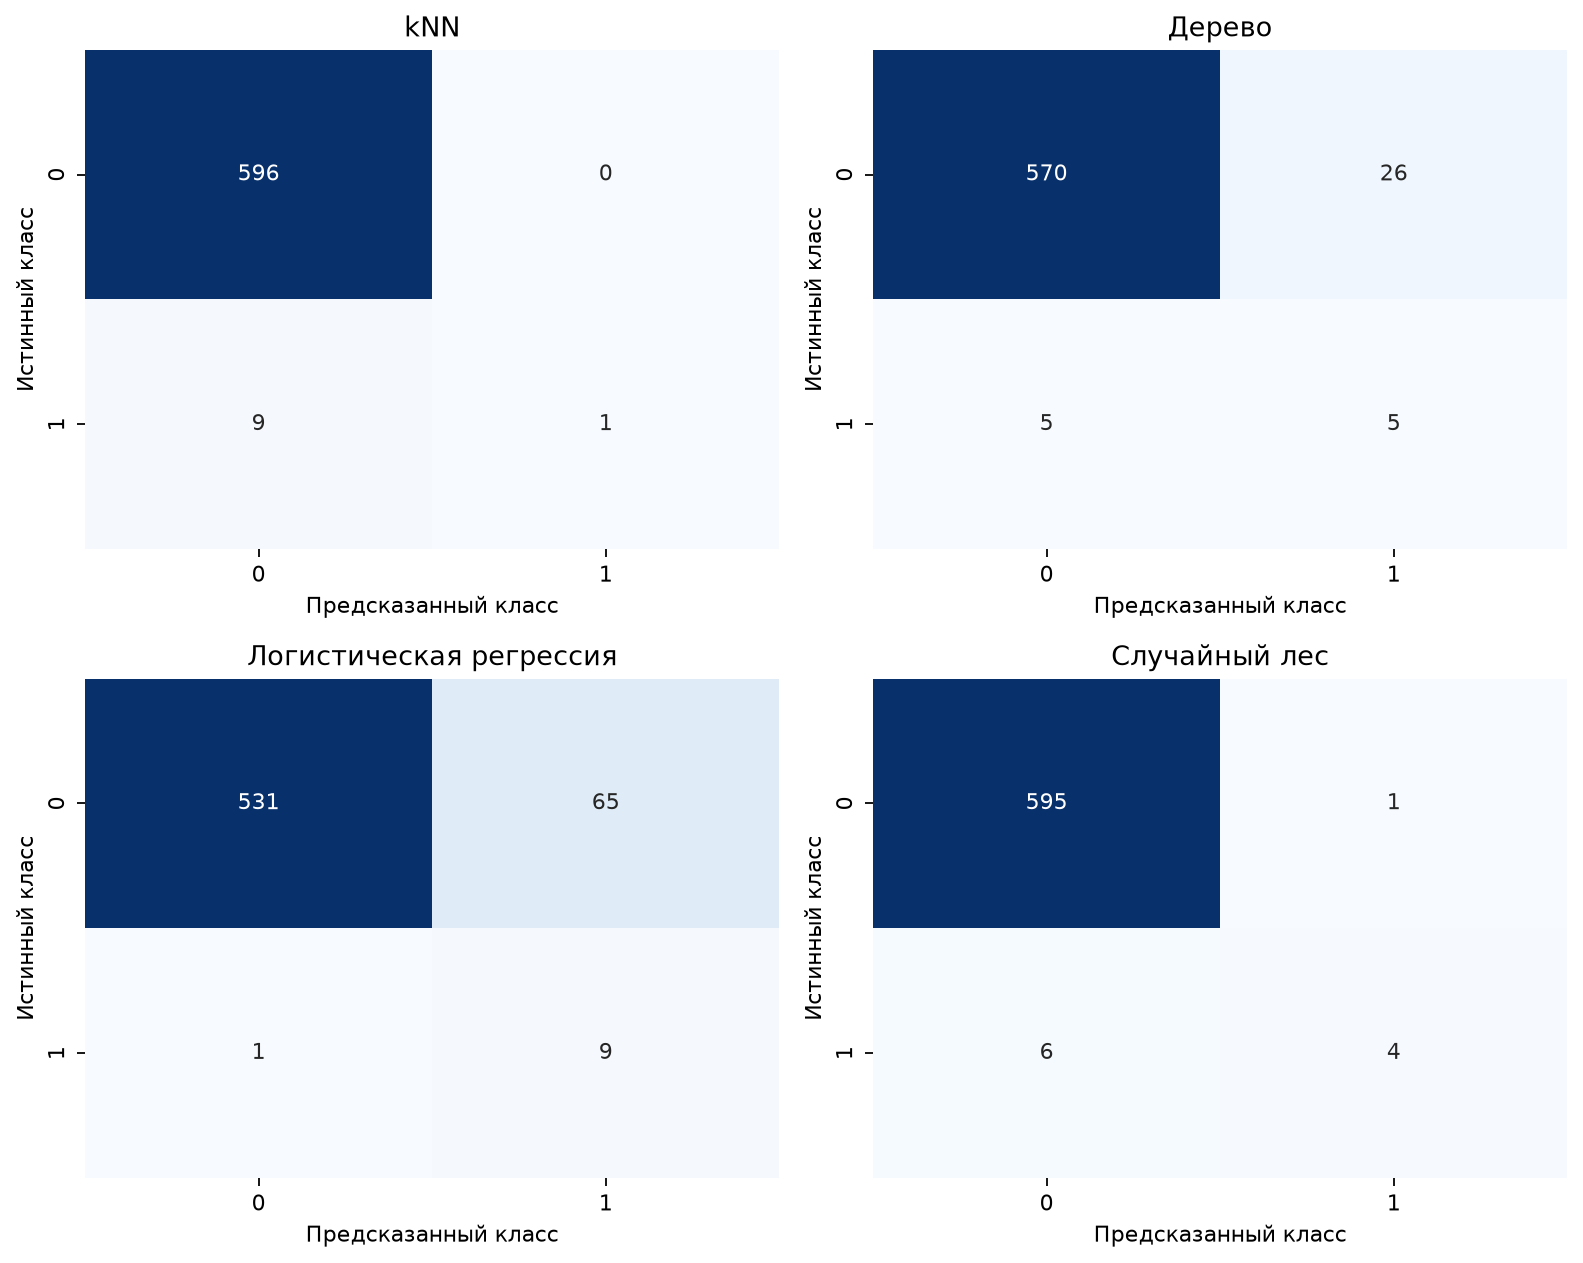

,TN,FP,FN,TP
Метод,,,,
kNN,596,0,9,1
Дерево,570,26,5,5
Логистическая регрессия,531,65,1,9
Случайный лес,595,1,6,4


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
confusion_rows = []
for ax, (name, pred) in zip(axes.flat, predictions.items()):
    matrix = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=[0, 1], yticklabels=[0, 1], ax=ax)
    ax.set(title=name, xlabel='Предсказанный класс', ylabel='Истинный класс')
    tn, fp, fn, tp = matrix.ravel()
    confusion_rows.append({'Метод': name, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
plt.tight_layout()
plt.show()
confusion_results = pd.DataFrame(confusion_rows).set_index('Метод')
display(confusion_results)

## 6 Сравнение ROC-кривых
На одном графике показаны четыре ROC-кривые. По горизонтали FPR=FP/(FP+TN), по вертикали TPR=Recall. Порог изменяется по вероятностям класса 1. Диагональ является ориентиром случайного ранжирования с AUC=0,5; она не означает равенства абсолютных количеств TP и FP. Площадь под ROC-кривой оценивает ранжирование объектов и не заменяет анализ Recall, Precision и F1 при выбранном пороге.

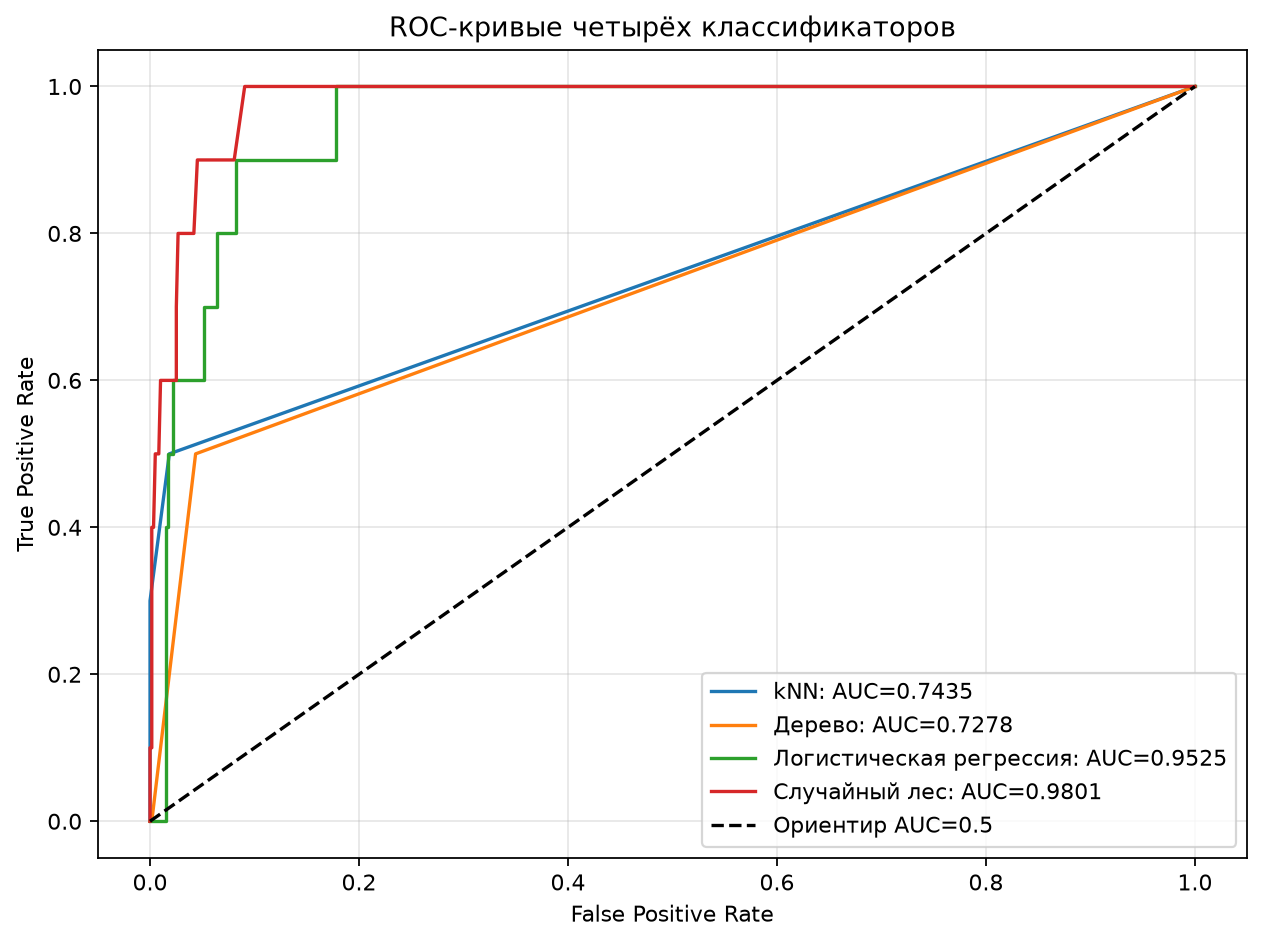

In [6]:
plt.figure(figsize=(8, 6))
for name, proba in probabilities.items():
    fpr, tpr, thresholds = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name}: AUC={auc:.4f}')
plt.plot([0, 1], [0, 1], 'k--', label='Ориентир AUC=0.5')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые четырёх классификаторов')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Выводы
Исследован medical_diagnosis.csv: 3031 строка, 14 столбцов. После удаления одного полного дубликата использованы 3030 наблюдений и восемь числовых признаков. Пропусков нет, заполнение и удаление экстремальных значений не применялись. Disease исключён из X. Класс 1 содержит 49 объектов (1,62%), класс 0 — 2981. Стратифицированное разделение 80/20 дало 2424 обучающих (2385/39) и 606 тестовых (596/10) объектов классов 0/1. Стандартизатор обучен только на train; тест не использован для подбора настроек.

Постоянный прогноз класса 0 даёт Accuracy=0,9835, Recall=0 и Balanced accuracy=0,5. Поэтому высокая Accuracy сама по себе не доказывает распознавание редкого класса.

kNN получил Accuracy=0,9851, но обнаружил лишь 1 из 10 положительных объектов (Recall=0,1). Дерево обнаружило 5 из 10 при 26 ложных срабатываниях. Логистическая регрессия обнаружила 9 из 10 (Recall=0,9; Balanced accuracy=0,8955), но дала 65 ложных срабатываний (Precision=0,1216). Случайный лес дал наибольшие F1=0,5333 и ROC AUC=0,9801 среди проверенных конфигураций; при этом он обнаружил только 4 из 10 положительных объектов, пропустив 6, и дал одно ложное срабатывание.

Для задачи с приоритетом полноты на этом тесте предпочтительнее логистическая регрессия; по F1 и ROC AUC среди изученных моделей лучше случайный лес. Универсального победителя по всем критериям нет. Веса balanced использовались в дереве, логистической регрессии и лесе из-за дисбаланса; у kNN они не применялись. Сравнение относится к указанным конфигурациям, а не ко всем возможным настройкам алгоритмов.

В тесте только 10 положительных наблюдений: один объект меняет Recall на 0,1. Оценки зависят от разбиения; проверка на независимых внешних данных не проводилась. Полученные прогнозы являются учебным результатом, а не медицинским диагнозом.

## Источник
Введение в анализ данных. Лабораторная работа 5. Классификация 2026: методические указания. 28 с. https://pro.guap.ru/inside/student/tasks/192889 (Дата обращения: 20.11.2026).